# AI-Based Network Threat Detection and Alert System
**Course:** Computer Networks | **Dataset:** NSL-KDD (Normal + 4 attack types: DoS, Probe, R2L, U2R) | **Models:** Random Forest + Deep Neural Network

**How to use**
1. Runtime -> Run all (training takes a few minutes).
2. At **Section 11**, click *Choose files* and upload your network-traffic CSV.
3. Read the alerts, the summary chart and download `detection_results.csv`.

Pipeline (report Figure 1): Data -> Pre-processing -> SMOTE -> PCA -> Train RF + DNN -> Evaluate -> Save best model -> **Upload file -> Detect attack type -> Alert**

## 1. Install and import

In [1]:
!pip install -q imbalanced-learn

import os, time, io, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
warnings.filterwarnings('ignore')

from sklearn.preprocessing import OneHotEncoder, MinMaxScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)
from imblearn.over_sampling import SMOTE

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
np.random.seed(42); tf.random.set_seed(42)

## 2. Dataset (NSL-KDD)
41 network-connection features per row. Attack names are grouped into 4 families:

| Class | Meaning |
|---|---|
| DoS | Flooding a host/service so it becomes unavailable |
| Probe | Scanning the network to gather information |
| R2L | Remote-to-Local: unauthorized access from a remote machine |
| U2R | User-to-Root: normal user gains administrator privileges |

If the automatic download fails you will be asked to upload `KDDTrain+.txt` and `KDDTest+.txt`.

In [2]:
cols = ['duration','protocol_type','service','flag','src_bytes','dst_bytes','land','wrong_fragment','urgent','hot',
 'num_failed_logins','logged_in','num_compromised','root_shell','su_attempted','num_root','num_file_creations',
 'num_shells','num_access_files','num_outbound_cmds','is_host_login','is_guest_login','count','srv_count',
 'serror_rate','srv_serror_rate','rerror_rate','srv_rerror_rate','same_srv_rate','diff_srv_rate',
 'srv_diff_host_rate','dst_host_count','dst_host_srv_count','dst_host_same_srv_rate','dst_host_diff_srv_rate',
 'dst_host_same_src_port_rate','dst_host_srv_diff_host_rate','dst_host_serror_rate','dst_host_srv_serror_rate',
 'dst_host_rerror_rate','dst_host_srv_rerror_rate']          # the 41 features
FULL = cols + ['label','difficulty']

URL = 'https://raw.githubusercontent.com/defcom17/NSL_KDD/master/'
try:
    train_raw = pd.read_csv(URL + 'KDDTrain+.txt', names=FULL)
    test_raw  = pd.read_csv(URL + 'KDDTest+.txt',  names=FULL)
    print('Downloaded NSL-KDD.')
except Exception as e:
    print('Download failed:', e)
    from google.colab import files
    print('Upload KDDTrain+.txt and KDDTest+.txt'); files.upload()
    train_raw = pd.read_csv('KDDTrain+.txt', names=FULL); test_raw = pd.read_csv('KDDTest+.txt', names=FULL)
print(train_raw.shape, test_raw.shape)
train_raw.head()

Downloaded NSL-KDD.
(125973, 43) (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


## 3. Map attack names to the 4 families

family
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64


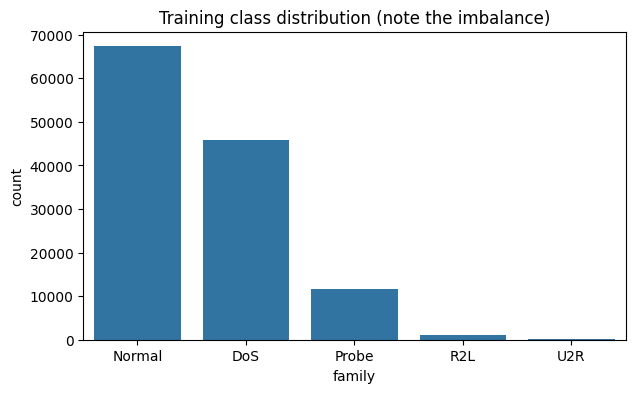

In [3]:
attack_map = {'normal':'Normal'}
for a in ['back','land','neptune','pod','smurf','teardrop','apache2','udpstorm','processtable','mailbomb','worm']: attack_map[a]='DoS'
for a in ['satan','ipsweep','nmap','portsweep','mscan','saint']: attack_map[a]='Probe'
for a in ['guess_passwd','ftp_write','imap','phf','multihop','warezmaster','warezclient','spy','xlock','xsnoop',
          'snmpguess','snmpgetattack','httptunnel','sendmail','named']: attack_map[a]='R2L'
for a in ['buffer_overflow','loadmodule','rootkit','perl','sqlattack','xterm','ps']: attack_map[a]='U2R'

for df in (train_raw, test_raw):
    df['family'] = df['label'].map(attack_map).fillna('Normal')

print(train_raw['family'].value_counts())
plt.figure(figsize=(7,4)); sns.countplot(x='family', data=train_raw, order=train_raw['family'].value_counts().index)
plt.title('Training class distribution (note the imbalance)'); plt.show()

ATTACK_INFO = {
 'Normal': ('NONE',     'Normal traffic'),
 'DoS'   : ('HIGH',     'Denial of Service - traffic flooding intended to make a host/service unavailable'),
 'Probe' : ('MEDIUM',   'Probing/scanning - attacker mapping hosts, ports and services (reconnaissance)'),
 'R2L'   : ('HIGH',     'Remote-to-Local - remote attacker trying to gain unauthorized local access (e.g. password guessing)'),
 'U2R'   : ('CRITICAL', 'User-to-Root - local user trying to escalate to administrator/root privileges')}

## 4. Pre-processing

In [4]:
train = train_raw.drop_duplicates(subset=cols + ['family']).dropna().reset_index(drop=True)
test  = test_raw.drop_duplicates(subset=cols + ['family']).dropna().reset_index(drop=True)

cat_cols = ['protocol_type','service','flag']
num_cols = [c for c in cols if c not in cat_cols]

le = LabelEncoder().fit(list(ATTACK_INFO.keys()))
class_names = list(le.classes_); NORMAL_ID = class_names.index('Normal')
y_train = le.transform(train['family']); y_test = le.transform(test['family'])

pre = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
    ('num', MinMaxScaler(clip=True), num_cols)])
X_train = pre.fit_transform(train[cols]); X_test = pre.transform(test[cols])
print('Encoded features:', X_train.shape[1], '| classes:', class_names)

Encoded features: 122 | classes: [np.str_('DoS'), np.str_('Normal'), np.str_('Probe'), np.str_('R2L'), np.str_('U2R')]


## 5. SMOTE (training set only)

In [5]:
counts = pd.Series(y_train).value_counts()
target = 5000
strategy = {int(k): target for k, v in counts.items() if v < target}
k = max(1, min(5, int(counts.min()) - 1))
X_res, y_res = SMOTE(sampling_strategy=strategy, k_neighbors=k, random_state=42).fit_resample(X_train, y_train)
print('Before:', {class_names[i]: int(v) for i, v in counts.items()})
print('After :', {class_names[i]: int(v) for i, v in pd.Series(y_res).value_counts().items()})

Before: {np.str_('Normal'): 67343, np.str_('DoS'): 45927, np.str_('Probe'): 11647, np.str_('R2L'): 995, np.str_('U2R'): 52}
After : {np.str_('Normal'): 67343, np.str_('DoS'): 45927, np.str_('Probe'): 11647, np.str_('R2L'): 5000, np.str_('U2R'): 5000}


## 6. PCA (95% variance)

In [6]:
pca = PCA(n_components=0.95, random_state=42)
X_res_p = pca.fit_transform(X_res); X_test_p = pca.transform(X_test)
print(f'Features: {X_res.shape[1]} -> {X_res_p.shape[1]}')

Features: 122 -> 28


## 7. Evaluation helper

In [7]:
def evaluate(name, y_true, y_pred, train_time):
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec  = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    f1   = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    yt = (np.array(y_true) != NORMAL_ID).astype(int); yp = (np.array(y_pred) != NORMAL_ID).astype(int)
    tn=((yt==0)&(yp==0)).sum(); fp=((yt==0)&(yp==1)).sum(); fn=((yt==1)&(yp==0)).sum(); tp=((yt==1)&(yp==1)).sum()
    print(f'\n===== {name} =====')
    print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))
    plt.figure(figsize=(6,5))
    sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion matrix - {name}'); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.show()
    return {'Model':name,'Accuracy':round(acc,4),'Precision':round(prec,4),'Recall':round(rec,4),'F-measure':round(f1,4),
            'FAR':round(fp/(fp+tn),4),'Detection Rate':round(tp/(tp+fn),4),'Training time (s)':round(train_time,1)}
results = []

## 8. Model 1 - Random Forest


===== Random Forest =====
              precision    recall  f1-score   support

         DoS       0.97      0.81      0.88      7460
      Normal       0.67      0.97      0.80      9711
       Probe       0.85      0.66      0.74      2418
         R2L       0.97      0.12      0.21      2885
         U2R       0.31      0.21      0.25        67

    accuracy                           0.77     22541
   macro avg       0.75      0.55      0.58     22541
weighted avg       0.83      0.77      0.74     22541



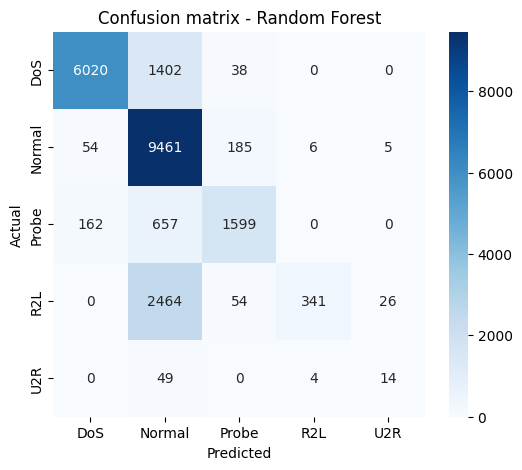

In [8]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42).fit(X_res_p, y_res)
results.append(evaluate('Random Forest', y_test, rf.predict(X_test_p), time.time()-t0))

## 9. Model 2 - Deep Neural Network

Epoch 1/20
475/475 - 5s - 11ms/step - accuracy: 0.9274 - loss: 0.2307 - val_accuracy: 0.9652 - val_loss: 0.0904
Epoch 2/20
475/475 - 2s - 5ms/step - accuracy: 0.9664 - loss: 0.0972 - val_accuracy: 0.9713 - val_loss: 0.0707
Epoch 3/20
475/475 - 2s - 5ms/step - accuracy: 0.9717 - loss: 0.0814 - val_accuracy: 0.9776 - val_loss: 0.0584
Epoch 4/20
475/475 - 3s - 5ms/step - accuracy: 0.9752 - loss: 0.0708 - val_accuracy: 0.9812 - val_loss: 0.0520
Epoch 5/20
475/475 - 2s - 5ms/step - accuracy: 0.9777 - loss: 0.0636 - val_accuracy: 0.9832 - val_loss: 0.0470
Epoch 6/20
475/475 - 3s - 6ms/step - accuracy: 0.9798 - loss: 0.0579 - val_accuracy: 0.9832 - val_loss: 0.0430
Epoch 7/20
475/475 - 3s - 6ms/step - accuracy: 0.9807 - loss: 0.0543 - val_accuracy: 0.9832 - val_loss: 0.0433
Epoch 8/20
475/475 - 2s - 5ms/step - accuracy: 0.9816 - loss: 0.0517 - val_accuracy: 0.9846 - val_loss: 0.0412
Epoch 9/20
475/475 - 2s - 5ms/step - accuracy: 0.9824 - loss: 0.0490 - val_accuracy: 0.9870 - val_loss: 0.0383


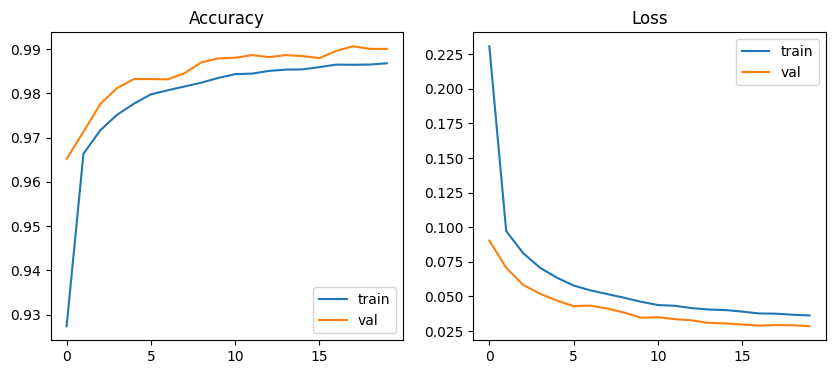


===== Deep Neural Network =====
              precision    recall  f1-score   support

         DoS       0.96      0.84      0.89      7460
      Normal       0.70      0.96      0.81      9711
       Probe       0.79      0.67      0.72      2418
         R2L       0.96      0.19      0.31      2885
         U2R       0.16      0.42      0.23        67

    accuracy                           0.79     22541
   macro avg       0.71      0.61      0.59     22541
weighted avg       0.83      0.79      0.76     22541



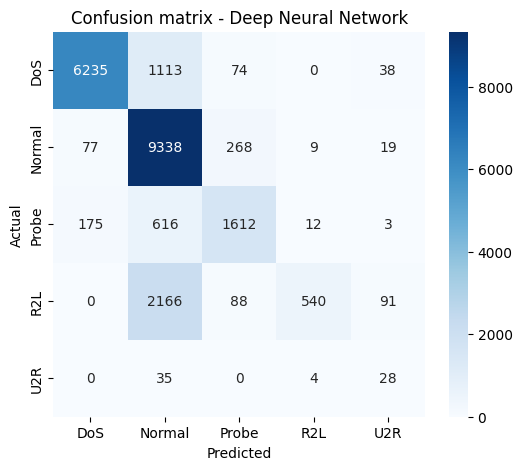

In [9]:
dnn = keras.Sequential([
    layers.Input(shape=(X_res_p.shape[1],)),
    layers.Dense(128, activation='relu'), layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),  layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dense(len(class_names), activation='softmax')])
dnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
# shuffle first: SMOTE appends its synthetic rows at the end, and Keras' validation_split takes the LAST 10%
perm = np.random.RandomState(42).permutation(len(y_res))
X_dnn, y_dnn = X_res_p[perm], y_res[perm]

t0 = time.time()
hist = dnn.fit(X_dnn, y_dnn, epochs=20, batch_size=256, validation_split=0.1, verbose=2)
dnn_time = time.time() - t0

plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.plot(hist.history['accuracy'], label='train'); plt.plot(hist.history['val_accuracy'], label='val'); plt.title('Accuracy'); plt.legend()
plt.subplot(1,2,2); plt.plot(hist.history['loss'], label='train'); plt.plot(hist.history['val_loss'], label='val'); plt.title('Loss'); plt.legend(); plt.show()
results.append(evaluate('Deep Neural Network', y_test, np.argmax(dnn.predict(X_test_p, verbose=0), axis=1), dnn_time))

## 10. Compare models, pick the best, and save it

,Model,Accuracy,Precision,Recall,F-measure,FAR,Detection Rate,Training time (s)
0,Random Forest,0.7735,0.8266,0.7735,0.7419,0.0257,0.6436,185.9
1,Deep Neural Network,0.7876,0.8288,0.7876,0.7643,0.0384,0.6937,53.1


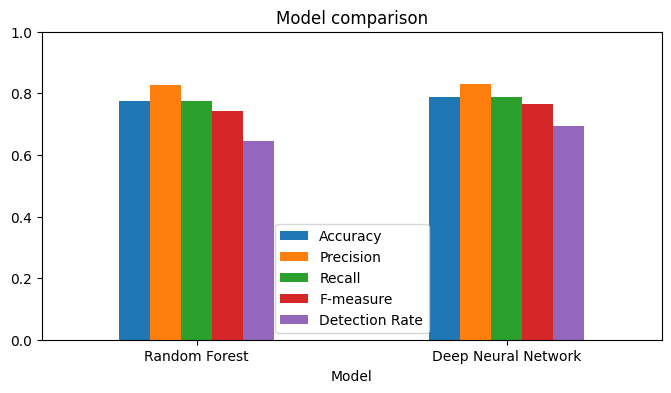

Best model used for detection: Deep Neural Network
Saved nids_pipeline.joblib and nids_dnn.keras


In [10]:
res_df = pd.DataFrame(results); display(res_df)
res_df.to_csv('results_table6.csv', index=False)
res_df.set_index('Model')[['Accuracy','Precision','Recall','F-measure','Detection Rate']].plot(kind='bar', figsize=(8,4))
plt.ylim(0,1); plt.title('Model comparison'); plt.xticks(rotation=0); plt.show()

best_name = res_df.sort_values('F-measure', ascending=False).iloc[0]['Model']
best_is_rf = best_name == 'Random Forest'
print('Best model used for detection:', best_name)

joblib.dump({'pre':pre, 'pca':pca, 'le':le, 'rf':rf, 'best_is_rf':best_is_rf}, 'nids_pipeline.joblib')
dnn.save('nids_dnn.keras')
print('Saved nids_pipeline.joblib and nids_dnn.keras')

## 11. Create sample test files (so you have something to upload)
Builds unlabeled sample files from the official NSL-KDD test set. Run this cell, then go to Section 12 and upload one of them (or any file of your own).

In [11]:
def make_sample(fam, n, name):
    s = test_raw[test_raw['family'] == fam].sample(n, random_state=1)
    s[cols].to_csv(name, index=False)
make_sample('DoS', 300, 'test_dos.csv'); make_sample('Probe', 300, 'test_probe.csv')
make_sample('R2L', 200, 'test_r2l.csv');  make_sample('U2R', 50, 'test_u2r.csv')
mix = pd.concat([test_raw[test_raw.family==f].sample(n, random_state=2) for f, n in
                 [('Normal',200),('DoS',150),('Probe',100),('R2L',50),('U2R',20)]]).sample(frac=1, random_state=3)
mix[cols].to_csv('test_mixed.csv', index=False)
mix[cols+['label']].to_csv('test_mixed_labeled.csv', index=False)
print('Created: test_dos.csv, test_probe.csv, test_r2l.csv, test_u2r.csv, test_mixed.csv, test_mixed_labeled.csv')
try:
    from google.colab import files
    for f in ['test_dos.csv','test_probe.csv','test_mixed.csv']: files.download(f)
except Exception: pass

Created: test_dos.csv, test_probe.csv, test_r2l.csv, test_u2r.csv, test_mixed.csv, test_mixed_labeled.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. TEST YOUR OWN FILE - detect which attack it is
**Accepted input:** a CSV (or NSL-KDD `.txt`) where each row is one network connection with the 41 NSL-KDD features.
* With header row (column names) or without header (raw NSL-KDD order) - both work.
* An extra `label` / `difficulty` column is fine. If a true label is present, accuracy is also reported.
* Don't have a file? Run Section 11 first to create sample files (`test_dos.csv`, `test_probe.csv`, `test_r2l.csv`, `test_u2r.csv`, `test_mixed.csv`).

Saving test_dos.csv to test_dos (1).csv
THREAT DETECTION REPORT  |  file: test_dos (1).csv  |  2026-11-01 12:01:04
Connections analysed : 300
Normal               : 46
Attacks detected     : 254



,Class,Count,Percent
0,DoS,252,84.0
1,Normal,46,15.3
2,Probe,2,0.7



[!!] MAIN THREAT: DoS (84.0% of traffic) - severity HIGH
     Denial of Service - traffic flooding intended to make a host/service unavailable

First 20 alerts:
[ALERT][HIGH] DoS attack | row=0 proto=tcp service=private flag=REJ src_bytes=0
[ALERT][HIGH] DoS attack | row=1 proto=tcp service=login flag=RSTO src_bytes=0
[ALERT][HIGH] DoS attack | row=2 proto=icmp service=ecr_i flag=SF src_bytes=1032
[ALERT][HIGH] DoS attack | row=3 proto=tcp service=login flag=RSTO src_bytes=0
[ALERT][HIGH] DoS attack | row=4 proto=icmp service=ecr_i flag=SF src_bytes=1008
[ALERT][HIGH] DoS attack | row=5 proto=tcp service=private flag=S0 src_bytes=0
[ALERT][HIGH] DoS attack | row=6 proto=tcp service=telnet flag=S3 src_bytes=0
[ALERT][HIGH] DoS attack | row=9 proto=tcp service=ctf flag=REJ src_bytes=0
[ALERT][HIGH] DoS attack | row=10 proto=tcp service=private flag=REJ src_bytes=0
[ALERT][HIGH] DoS attack | row=11 proto=tcp service=http flag=RSTR src_bytes=72564
[ALERT][HIGH] DoS attack | row=13 proto=t

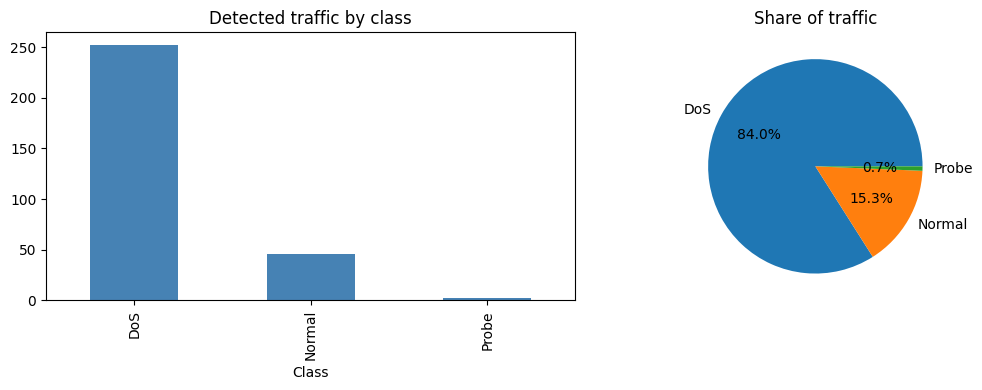


Saved: detection_results.csv, alerts_log.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
def read_traffic_file(path):
    # try with header first
    df = pd.read_csv(path, sep=None, engine='python')
    if not set(cols).issubset(df.columns):
        df = pd.read_csv(path, header=None, sep=None, engine='python')       # headerless raw NSL-KDD
        if df.shape[1] in (41, 42, 43):
            df.columns = (FULL)[:df.shape[1]]
        else:
            raise ValueError(f'Unsupported file: found {df.shape[1]} columns, expected the 41 NSL-KDD features '
                             f'(optionally followed by label/difficulty).')
    missing = [c for c in cols if c not in df.columns]
    if missing:
        raise ValueError(f'Missing required columns: {missing[:8]} ...')
    return df

def predict_attack(df):
    Xp = pca.transform(pre.transform(df[cols]))
    if best_is_rf:
        return le.inverse_transform(rf.predict(Xp))
    return le.inverse_transform(np.argmax(dnn.predict(Xp, verbose=0), axis=1))

def detect(path, max_alerts=20):
    df = read_traffic_file(path).reset_index(drop=True)
    df['predicted_attack'] = predict_attack(df)
    df['severity'] = df['predicted_attack'].map(lambda a: ATTACK_INFO[a][0])
    n = len(df); atk = df[df['predicted_attack'] != 'Normal']

    print('='*70); print(f'THREAT DETECTION REPORT  |  file: {os.path.basename(path)}  |  {datetime.now():%Y-%m-%d %H:%M:%S}'); print('='*70)
    print(f'Connections analysed : {n}\nNormal               : {n-len(atk)}\nAttacks detected     : {len(atk)}\n')

    summary = df['predicted_attack'].value_counts().rename_axis('Class').reset_index(name='Count')
    summary['Percent'] = (summary['Count']/n*100).round(1)
    display(summary)

    if len(atk) == 0:
        print('\n[OK] No threats detected. Traffic looks normal.')
    else:
        top = atk['predicted_attack'].value_counts().idxmax(); share = (atk['predicted_attack']==top).sum()/n*100
        print(f"\n[!!] MAIN THREAT: {top} ({share:.1f}% of traffic) - severity {ATTACK_INFO[top][0]}")
        print('     ' + ATTACK_INFO[top][1])
        print(f'\nFirst {min(max_alerts, len(atk))} alerts:')
        for idx, r in atk.head(max_alerts).iterrows():
            print(f"[ALERT][{r['severity']}] {r['predicted_attack']} attack | row={idx} proto={r['protocol_type']} "
                  f"service={r['service']} flag={r['flag']} src_bytes={r['src_bytes']}")
        if len(atk) > max_alerts: print(f'... and {len(atk)-max_alerts} more (see detection_results.csv)')

    fig, ax = plt.subplots(1, 2, figsize=(11,4))
    summary.set_index('Class')['Count'].plot(kind='bar', ax=ax[0], color='steelblue'); ax[0].set_title('Detected traffic by class')
    ax[1].pie(summary['Count'], labels=summary['Class'], autopct='%1.1f%%'); ax[1].set_title('Share of traffic')
    plt.tight_layout(); plt.show()

    # if the file carries a true label, report accuracy
    truth = None
    if 'family' in df.columns: truth = df['family']
    elif 'label' in df.columns: truth = df['label'].astype(str).str.strip().str.rstrip('.').map(attack_map)
    if truth is not None and truth.notna().all():
        print(f"\nTrue labels found - accuracy on this file: {accuracy_score(truth, df['predicted_attack'])*100:.2f}%")
        print(classification_report(truth, df['predicted_attack'], zero_division=0))

    out = df.drop(columns=[c for c in ['family'] if c in df.columns])
    out.to_csv('detection_results.csv', index=False)
    alert_log = atk[['predicted_attack','severity','protocol_type','service','flag','src_bytes','dst_bytes']].copy()
    alert_log.insert(0, 'time', datetime.now().strftime('%Y-%m-%d %H:%M:%S')); alert_log.to_csv('alerts_log.csv', index=False)
    print('\nSaved: detection_results.csv, alerts_log.csv')
    return df

# ---- upload your file here ----
try:
    from google.colab import files
    up = files.upload()
    uploaded_path = list(up.keys())[0]
except Exception:
    uploaded_path = os.environ.get('TEST_FILE', 'test_mixed.csv')
result_df = detect(uploaded_path)
try:
    files.download('detection_results.csv')
except Exception: pass